In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# 1. Load dataset (exact name matching your uploaded file)
df = pd.read_csv('Dataset .csv')

# 2. Inspect dataset
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


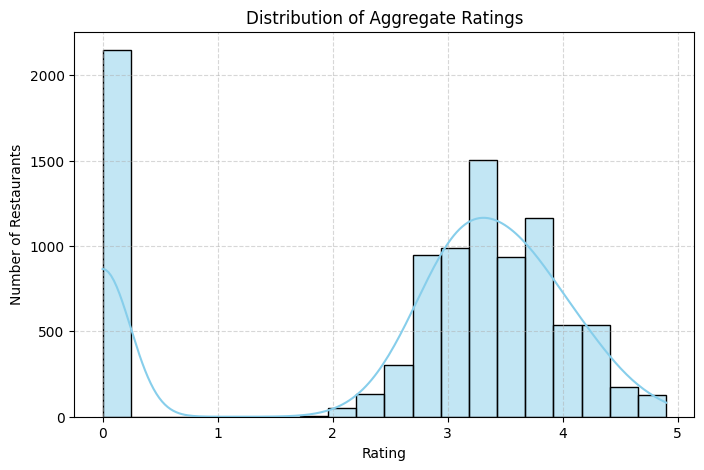

--- Most Common Rating Ranges ---
Rating Range
(3.0, 3.5]    2502
(2.0, 3.0]    1891
(3.5, 4.0]    1886
(4.0, 4.5]     908
(4.5, 5.0]     206
(0.0, 2.0]      10
Name: count, dtype: int64

Average Votes per Restaurant: 156.91


In [2]:
# Task 1: Restaurant Ratings Analysis

# 1. Plot distribution of Aggregate Ratings
plt.figure(figsize=(8, 5))
sns.histplot(df['Aggregate rating'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Aggregate Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('task1_rating_distribution.png')
plt.show()

# 2. Determine most common rating range
df['Rating Range'] = pd.cut(df['Aggregate rating'], bins=[0, 2, 3, 3.5, 4, 4.5, 5])
common_range = df['Rating Range'].value_counts()
print("--- Most Common Rating Ranges ---")
print(common_range)

# 3. Average number of votes
avg_votes = df['Votes'].mean()
print(f"\nAverage Votes per Restaurant: {avg_votes:.2f}")

--- Top 10 Most Common Cuisine Combinations ---
Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64


/tmp/ipykernel_1696/2966801211.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_combos.values, y=top_combos.index, palette='crest')


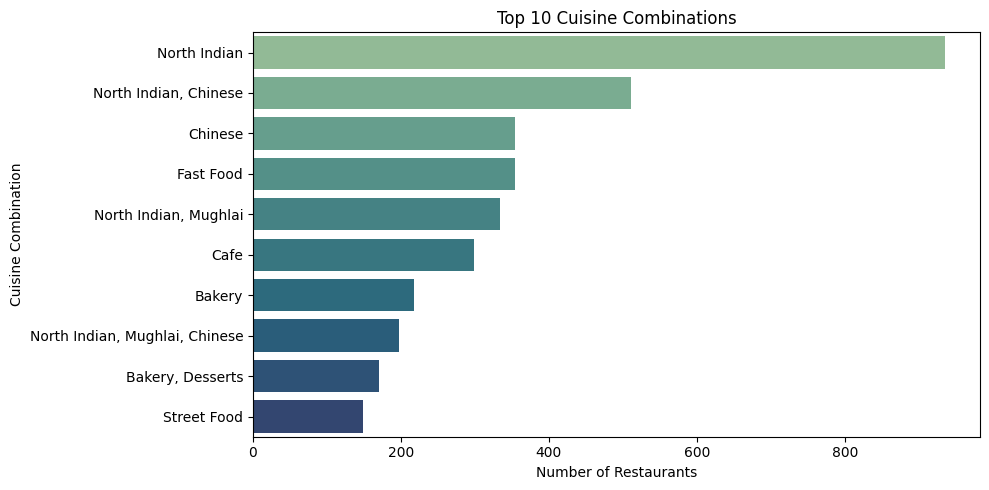


--- Average Ratings for Top Cuisine Combinations ---
                                Average Rating  Count
Cuisines                                             
Cafe                                  2.890970    299
North Indian, Mughlai                 2.888623    334
North Indian, Mughlai, Chinese        2.568528    197
North Indian, Chinese                 2.421722    511
Bakery, Desserts                      2.317647    170
Street Food                           2.161745    149
Fast Food                             2.118362    354
Chinese                               2.042090    354
Bakery                                1.924312    218
North Indian                          1.672329    936


In [3]:
# Task 2: Cuisine Combination Analysis

# 1. Top 10 most common cuisine combinations
top_combos = df['Cuisines'].value_counts().head(10)
print("--- Top 10 Most Common Cuisine Combinations ---")
print(top_combos)

# 2. Bar plot of top cuisine combinations
plt.figure(figsize=(10, 5))
sns.barplot(x=top_combos.values, y=top_combos.index, palette='crest')
plt.title('Top 10 Cuisine Combinations')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine Combination')
plt.tight_layout()
plt.savefig('task2_cuisine_combos.png')
plt.show()

# 3. Average rating for top cuisine combinations
combo_ratings = df.groupby('Cuisines')['Aggregate rating'].agg(['mean', 'count']).loc[top_combos.index]
combo_ratings.columns = ['Average Rating', 'Count']
print("\n--- Average Ratings for Top Cuisine Combinations ---")
print(combo_ratings.sort_values(by='Average Rating', ascending=False))

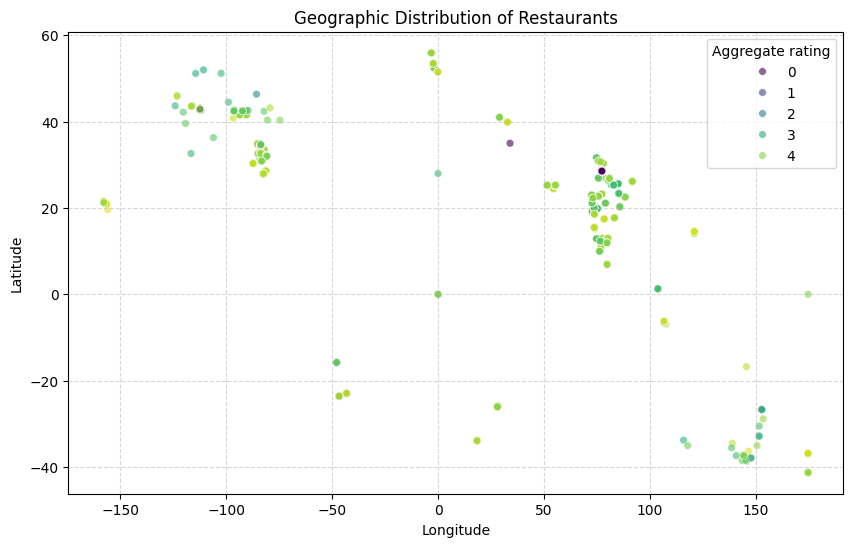

Interactive map successfully saved as restaurant_locations_map.html


In [4]:
# Task 3: Geographic Analysis

# 1. Static Scatterplot of Coordinates
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Longitude',
    y='Latitude',
    hue='Aggregate rating',
    palette='viridis',
    alpha=0.6,
    s=30
)
plt.title('Geographic Distribution of Restaurants')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('task3_geographic_clusters.png')
plt.show()

# 2. Interactive Map (Folium) - sample first 300 rows for smooth performance
map_center = [df['Latitude'].mean(), df['Longitude'].mean()]
m = folium.Map(location=map_center, zoom_start=10)

for _, row in df.dropna(subset=['Latitude', 'Longitude']).head(300).iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=3,
        popup=f"{row['Restaurant Name']} ({row['Aggregate rating']}⭐)",
        color='crimson',
        fill=True,
        fill_opacity=0.6
    ).add_to(m)

# Save map as an HTML file
m.save('restaurant_locations_map.html')
print("Interactive map successfully saved as restaurant_locations_map.html")

Total Restaurant Chains Found: 734

--- Top 10 Restaurant Chains ---
                  Outlets  Avg_Rating  Total_Votes
Restaurant Name                                   
Cafe Coffee Day        83    2.419277         2428
Domino's Pizza         79    2.740506         6643
Subway                 63    2.907937         6124
Green Chick Chop       51    2.672549          964
McDonald's             48    3.339583         5291
Keventers              34    2.870588         1263
Pizza Hut              30    3.320000         4961
Giani                  29    2.689655          854
Baskin Robbins         28    1.860714          428
Barbeque Nation        26    4.353846        28142


/tmp/ipykernel_1696/2909259121.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=chain_analysis.head(10)['Outlets'], y=chain_analysis.head(10).index, palette='flare')


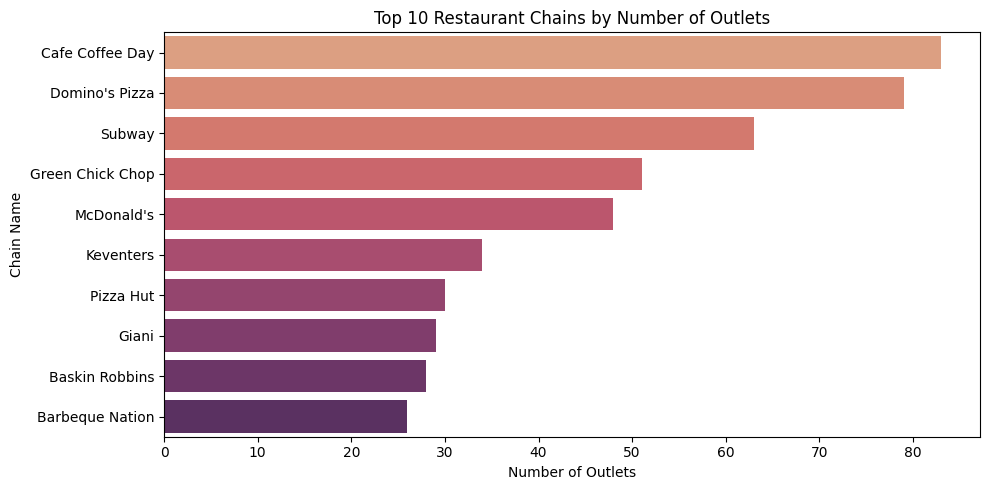

In [5]:
# Task 4: Restaurant Chains Analysis

# 1. Identify chains (appearing more than once in the dataset)
chain_counts = df['Restaurant Name'].value_counts()
chains_list = chain_counts[chain_counts > 1].index

print(f"Total Restaurant Chains Found: {len(chains_list)}")

# 2. Analyze top chains by number of outlets, average rating, and total votes
chain_analysis = df[df['Restaurant Name'].isin(chains_list)].groupby('Restaurant Name').agg(
    Outlets=('Restaurant Name', 'count'),
    Avg_Rating=('Aggregate rating', 'mean'),
    Total_Votes=('Votes', 'sum')
).sort_values(by='Outlets', ascending=False)

print("\n--- Top 10 Restaurant Chains ---")
print(chain_analysis.head(10))

# 3. Bar plot for top chains by outlet count
plt.figure(figsize=(10, 5))
sns.barplot(x=chain_analysis.head(10)['Outlets'], y=chain_analysis.head(10).index, palette='flare')
plt.title('Top 10 Restaurant Chains by Number of Outlets')
plt.xlabel('Number of Outlets')
plt.ylabel('Chain Name')
plt.tight_layout()
plt.savefig('task4_top_chains.png')
plt.show()